# Описание
Загружаем оценки численности населения Бразилии, Китая и Индии за 2015–2024 годы из World Bank Indicators API в PostgreSQL. Одна запись в stg.population соответствует одной стране и одному году (полный набор содержит 30 наблюдений)

## Импорты

In [1]:
import sys
from IPython.display import display
import logging
import os
from pathlib import Path

import psycopg
import requests
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

## Конфигурация

In [ ]:
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "docker-compose.yml").is_file() and (p / "init/init.sql").is_file()), None)
if root is None or not (root / ".env").is_file():
    raise FileNotFoundError("Запустите bash scripts/run.sh из каталога проекта для создания .env.")

load_dotenv(root / ".env")
def setting(name):
    value = os.getenv(name)
    if not value:
        raise ValueError(f"Заполните {name} в .env.")
    return value

db_config = {
    "host": setting("POSTGRES_HOST"), "port": int(setting("POSTGRES_PORT")),
    "dbname": setting("POSTGRES_DB"), "user": setting("POSTGRES_USER"),
    "password": setting("POSTGRES_PASSWORD"), "connect_timeout": 8,
}


countries = ("BRA", "CHN", "IND")
years = range(2015, 2025)
indicator = "SP.POP.TOTL"
endpoint = f"{setting('WB_API_BASE').rstrip('/')}/country/{';'.join(countries)}/indicator/{indicator}"
query = {"source": 2, "format": "json", "date": f"{years.start}:{years.stop - 1}", "per_page": 7}
expected_keys = {(country, year) for country in countries for year in years}

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", force=True)
log = logging.getLogger("population")

## Extract

In [ ]:
# API возвращает метаданные и список наблюдений
# Читаем все страницы по pages, сверяем номера страниц и общее число записей
# Тайм-аут ограничивает ожидание ответа, а для GET включены повторы при временных сбоях
def extract(session):
    records = []
    page = 1
    while True:
        response = session.get(endpoint, params={**query, "page": page}, timeout=(5, 20))
        response.raise_for_status()
        payload = response.json()
        if not (isinstance(payload, list) and len(payload) == 2
                and isinstance(payload[0], dict) and isinstance(payload[1], list)):
            raise ValueError(f"Неожиданный формат ответа API на странице {page}.")
        meta, batch = payload
        pages, total = int(meta["pages"]), int(meta["total"])
        if page == 1:
            expected_pages, expected_total = pages, total
        if (int(meta["page"]) != page or pages != expected_pages or total != expected_total
                or not 1 <= page <= pages or not batch or total != len(expected_keys)):
            raise ValueError(f"Неполная или несогласованная выдача API на странице {page}.")
        records.extend(batch)
        log.info("Extract | страница %d/%d, получено %d строк", page, pages, len(batch))
        if page == pages:
            break
        page += 1
    if len(records) != expected_total:
        raise ValueError(f"API объявил {expected_total} строк, получено {len(records)}.")
    return records

retry = Retry(total=3, backoff_factor=0.5, status_forcelist=(429, 500, 502, 503, 504),
              allowed_methods={"GET"})
try:
    with requests.Session() as session:
        session.mount("https://", HTTPAdapter(max_retries=retry))
        raw_records = extract(session)
except (requests.RequestException, ValueError, KeyError, TypeError) as error:
    log.error("Extract | выгрузка прервана: %s", error)
    raise

2026-11-21 15:09:04,708 INFO Extract | страница 1/5, получено 7 строк


2026-11-21 15:09:04,780 INFO Extract | страница 2/5, получено 7 строк


2026-11-21 15:09:04,843 INFO Extract | страница 3/5, получено 7 строк


2026-11-21 15:09:04,921 INFO Extract | страница 4/5, получено 7 строк


2026-11-21 15:09:04,985 INFO Extract | страница 5/5, получено 2 строк


## Transform
Из вложенного JSON извлекаем название страны, приводим год к целому и проверяем единицу наблюдения (при пропуске значения, повторе ключа или неожиданной стране загрузка прерывается до записи в БД)

In [4]:
def transform(records):
    rows = {}
    for record in records:
        country = record["countryiso3code"].strip().upper()
        year = int(record["date"])
        key = (country, year)
        name = record["country"]["value"].strip()
        value = record["value"]
        if key not in expected_keys or record["indicator"]["id"] != indicator:
            raise ValueError(f"Неожиданное наблюдение: {key}.")
        if key in rows:
            raise ValueError(f"Повтор ключа в API: {key}.")
        if not name or type(value) is not int or value < 0:
            raise ValueError(f"Некорректное название страны или численность населения: {key}.")
        rows[key] = (country, year, name, value)
    missing = expected_keys.difference(rows)
    if missing:
        raise ValueError(f"Отсутствуют наблюдения: {sorted(missing)}.")
    return [rows[key] for key in sorted(rows)]

try:
    population_rows = transform(raw_records)
except (ValueError, TypeError, KeyError, AttributeError) as error:
    log.error("Transform | ошибка данных: %s", error)
    raise
log.info("Transform | проверено %d уникальных пар страна–год", len(population_rows))

2026-11-21 15:09:04,999 INFO Transform | проверено 30 уникальных пар страна–год


## Load
По ключу (country_code, year) вставляем новые наблюдения и обновляем пересмотренные оценки. Условие IS DISTINCT FROM пропускает совпадающие значения. Весь пакет записывается одной транзакцией

In [5]:
upsert = '''
    INSERT INTO stg.population AS p (country_code, year, country_name, population)
    VALUES (%s, %s, %s, %s)
    ON CONFLICT (country_code, year) DO UPDATE
    SET country_name = EXCLUDED.country_name, population = EXCLUDED.population
    WHERE (p.country_name, p.population)
          IS DISTINCT FROM (EXCLUDED.country_name, EXCLUDED.population)
'''
try:
    with psycopg.connect(**db_config) as conn:
        with conn.cursor() as cur:
            cur.executemany(upsert, population_rows)
            changed = cur.rowcount
except psycopg.Error:
    log.exception("Load | проверьте docker compose ps, доступ к PostgreSQL и init/init.sql.")
    raise
log.info("Load | транзакция завершена, вставлено или обновлено строк: %d", changed)

2026-11-21 15:09:05,035 INFO Load | транзакция завершена, вставлено или обновлено строк: 0


## Проверка
Открываем новое соединение после фиксации транзакции. Сверяем число записей, число уникальных ключей и все значения с результатом Transform. Выводим первые пять строк в порядке кода страны и года

stg.population | rows: 30 | unique keys: 30
country_code  year   country_name     population
BRA           2015   Brazil          201,675,532
BRA           2016   Brazil          203,218,114
BRA           2017   Brazil          204,703,445
BRA           2018   Brazil          206,107,261
BRA           2019   Brazil          207,455,459


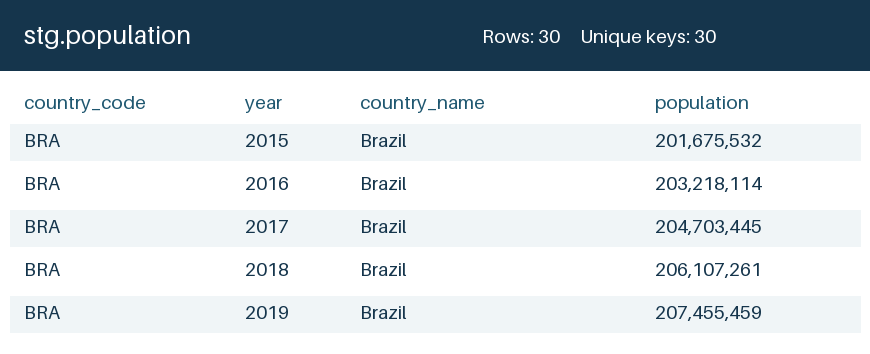

In [ ]:
ordered_query = '''
    SELECT country_code, year, country_name, population
    FROM stg.population
    ORDER BY country_code, year
'''
try:
    with psycopg.connect(**db_config) as conn:
        total, unique = conn.execute(
            "SELECT COUNT(*), COUNT(DISTINCT (country_code, year)) FROM stg.population"
        ).fetchone()
        if total != unique or conn.execute(ordered_query).fetchall() != population_rows:
            raise ValueError("Содержимое PostgreSQL расходится с результатом Transform.")
        preview = conn.execute(ordered_query + " LIMIT 5").fetchall()
except (psycopg.Error, ValueError):
    log.exception("Проверка | не удалось подтвердить результат в PostgreSQL.")
    raise

print(f"stg.population | rows: {total} | unique keys: {unique}")
print(f"{'country_code':<14}{'year':<7}{'country_name':<15}{'population':>12}")
for country, year, name, population in preview:
    print(f"{country:<14}{year:<7}{name:<15}{population:>12,}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

    
from scripts.result_image import draw_result
display(draw_result(total, unique, preview))